# MCF10A dose figure reproduction

This notebook reproduces every plot in `SE_MCF10A_Dose.ipynb` from the packaged per-cell table. It does not load AnnData or rerun the upstream pipeline.

Input: `source_data/Input_MCF10A_Dose_percell.csv`. Figures and derived statistics are written to `figures/` and `source_data/`.

In [7]:
from itertools import combinations
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr, spearmanr, ttest_ind
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

SOURCE = Path('source_data')
FIGURES = Path('figures')
SOURCE.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)

mpl.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 600, 'savefig.bbox': 'tight', 'pdf.fonttype': 42, 'ps.fonttype': 42})
sns.set_theme(style='white', context='paper')

DOSE_ORDER = [0.0, 12.5, 25.0, 50.0, 100.0, 200.0, 400.0, 800.0]
DOSE_LABELS = [f'{dose:g}' for dose in DOSE_ORDER]
DOSE_COLORS = {0.0:'tab:blue', 12.5:'tab:orange', 25.0:'tab:green', 50.0:'tab:red', 100.0:'tab:purple', 200.0:'tab:brown', 400.0:'tab:pink', 800.0:'gold'}
PASTEL_COLORS = ['#B8D8E8','#BFD4EA','#C9C4E4','#D3BBDD','#DEB6D5','#E8B8C8','#F0C1B8','#F4C9A8']

cells = pd.read_csv(SOURCE / 'Input_MCF10A_Dose_percell.csv', index_col='cell_id')
cells['Dose_pM'] = pd.to_numeric(cells['Dose_pM'])

def save_figure(fig, name):
    fig.savefig(FIGURES / f'{name}.png')
    fig.savefig(FIGURES / f'{name}.pdf')

def dose_groups(column):
    return [cells.loc[cells['Dose_pM'] == dose, column].dropna().to_numpy() for dose in DOSE_ORDER]

print(f'{len(cells):,} cells; missing values: {int(cells.isna().sum().sum())}')

8,882 cells; missing values: 0


## CCAT plots

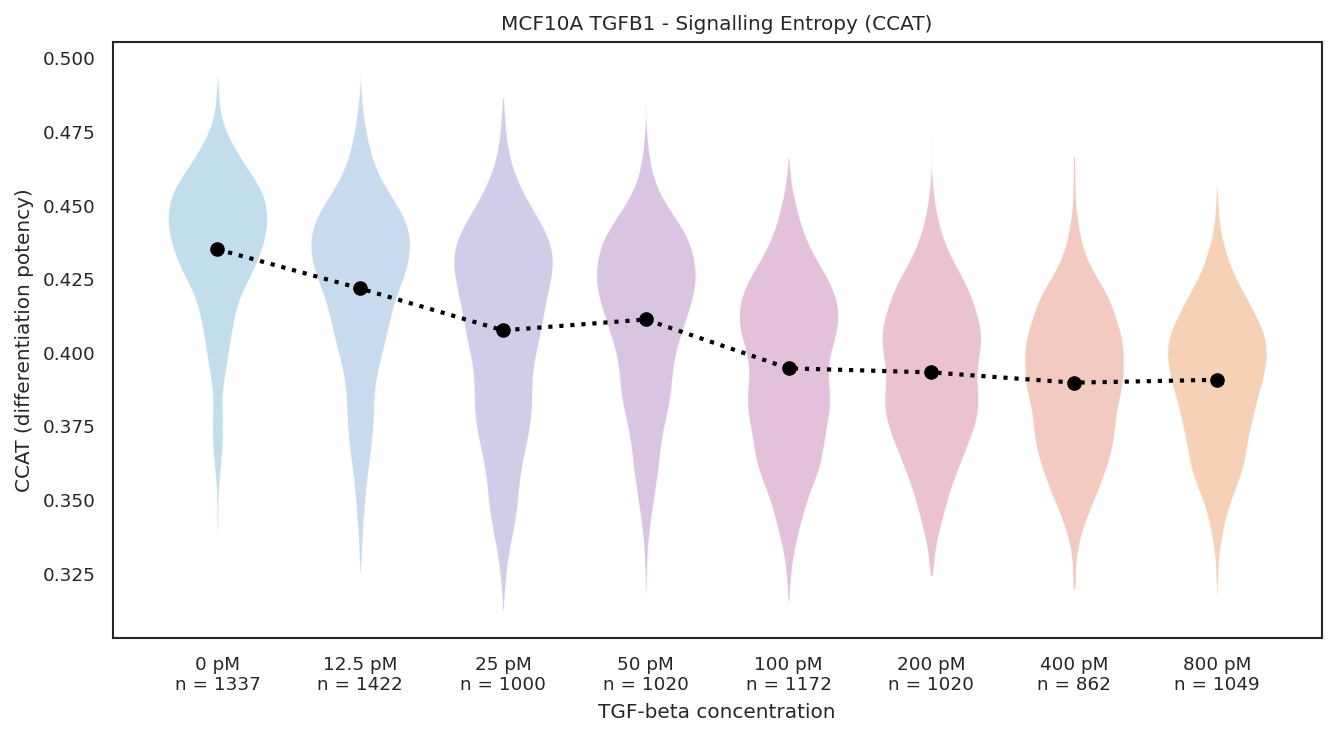

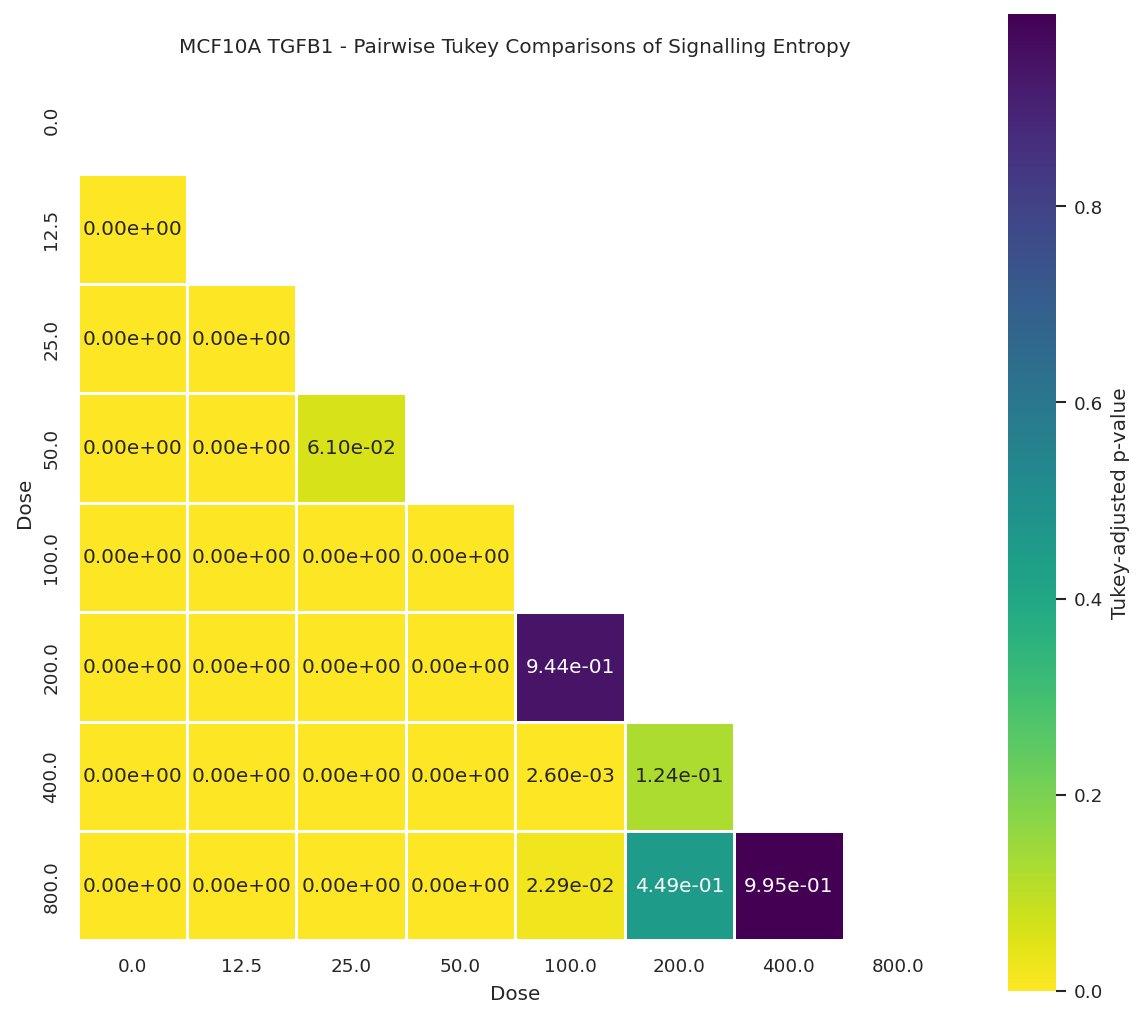

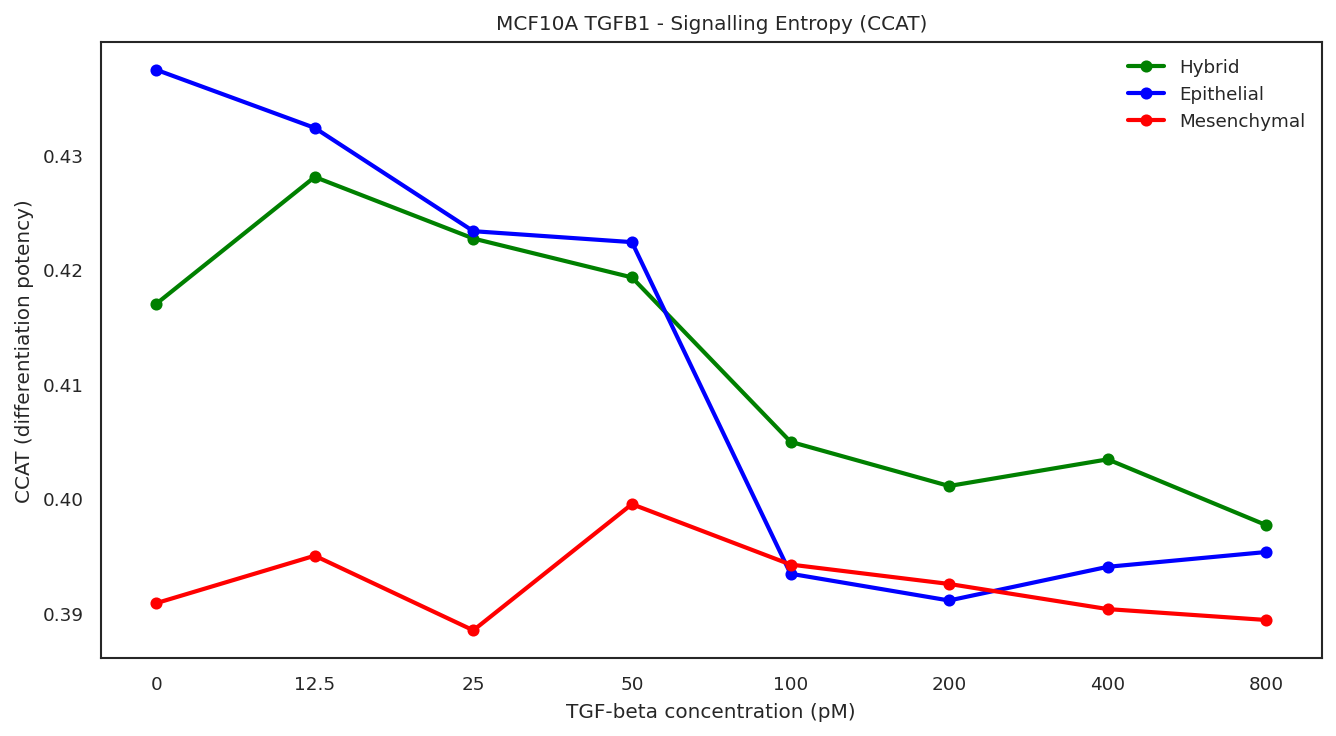

In [2]:
ccat_groups = dose_groups('CCAT')
ccat_means = [values.mean() for values in ccat_groups]
counts = cells['Dose_pM'].value_counts().reindex(DOSE_ORDER)
x = np.arange(len(DOSE_ORDER))

fig, ax = plt.subplots(figsize=(9, 5))
parts = ax.violinplot(ccat_groups, positions=x, widths=0.7, showmeans=False, showmedians=False, showextrema=False)
for body, color in zip(parts['bodies'], PASTEL_COLORS): body.set_facecolor(color); body.set_alpha(0.85)
ax.plot(x, ccat_means, ':o', linewidth=2, markersize=6, color='black')
ax.set_xticks(x); ax.set_xticklabels([f'{dose:g} pM\nn = {int(counts.loc[dose])}' for dose in DOSE_ORDER])
ax.set_xlabel('TGF-beta concentration'); ax.set_ylabel('CCAT (differentiation potency)')
ax.set_title('MCF10A TGFB1 - Signalling Entropy (CCAT)')
fig.tight_layout(); save_figure(fig, 'panel01_ccat_across_dose'); plt.show()

tukey = pairwise_tukeyhsd(cells['CCAT'], cells['Dose_pM'], alpha=0.05)
tukey_df = pd.DataFrame(tukey._results_table.data[1:], columns=tukey._results_table.data[0])
tukey_df['p-adj'] = tukey_df['p-adj'].astype(float)
ccat_p = pd.DataFrame(np.nan, index=DOSE_ORDER, columns=DOSE_ORDER)
for _, row in tukey_df.iterrows(): ccat_p.loc[float(row['group1']), float(row['group2'])] = row['p-adj']; ccat_p.loc[float(row['group2']), float(row['group1'])] = row['p-adj']
ccat_p.to_csv(SOURCE / 'MCF10A_panel01_ccat_tukey_matrix.csv')
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(ccat_p, mask=np.triu(np.ones_like(ccat_p, dtype=bool)), annot=True, fmt='.2e', cmap='viridis_r', linewidths=0.5, square=True, cbar_kws={'label':'Tukey-adjusted p-value'}, ax=ax)
ax.set_title('MCF10A TGFB1 - Pairwise Tukey Comparisons of Signalling Entropy'); ax.set_xlabel('Dose'); ax.set_ylabel('Dose')
fig.tight_layout(); save_figure(fig, 'panel02_ccat_tukey'); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for phenotype, color in {'hybrid':'green','epithelial':'blue','mesenchymal':'red'}.items():
    subset = cells[cells['phenotype'] == phenotype]
    means = subset.groupby('Dose_pM')['CCAT'].mean().reindex(DOSE_ORDER)
    ax.plot(x, means, marker='o', linewidth=2, color=color, label=phenotype.capitalize())
ax.set_xticks(x); ax.set_xticklabels(DOSE_LABELS); ax.set_xlabel('TGF-beta concentration (pM)'); ax.set_ylabel('CCAT (differentiation potency)')
ax.set_title('MCF10A TGFB1 - Signalling Entropy (CCAT)'); ax.legend(frameon=False)
fig.tight_layout(); save_figure(fig, 'panel03_ccat_by_phenotype'); plt.show()

## Shannon entropy plots

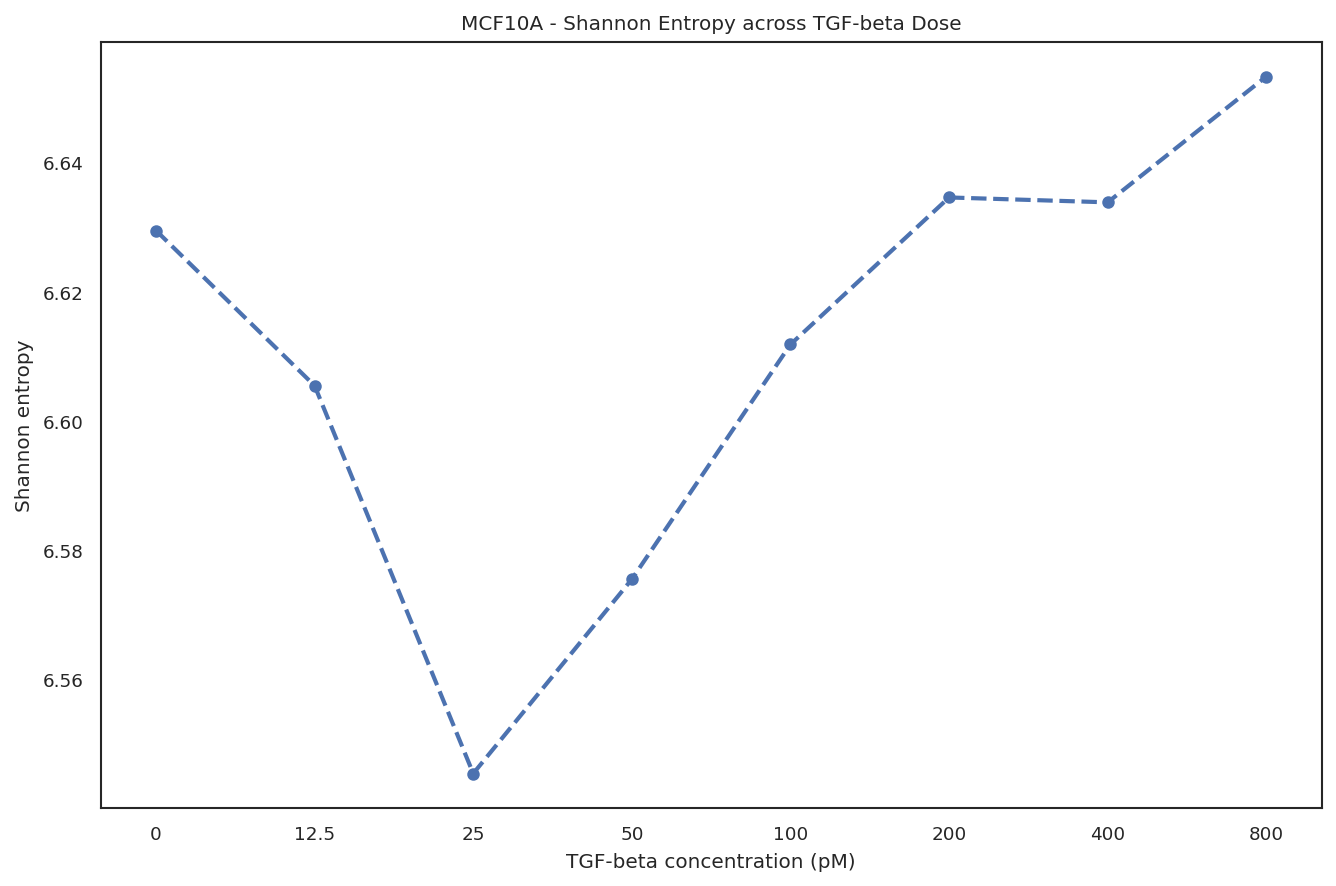

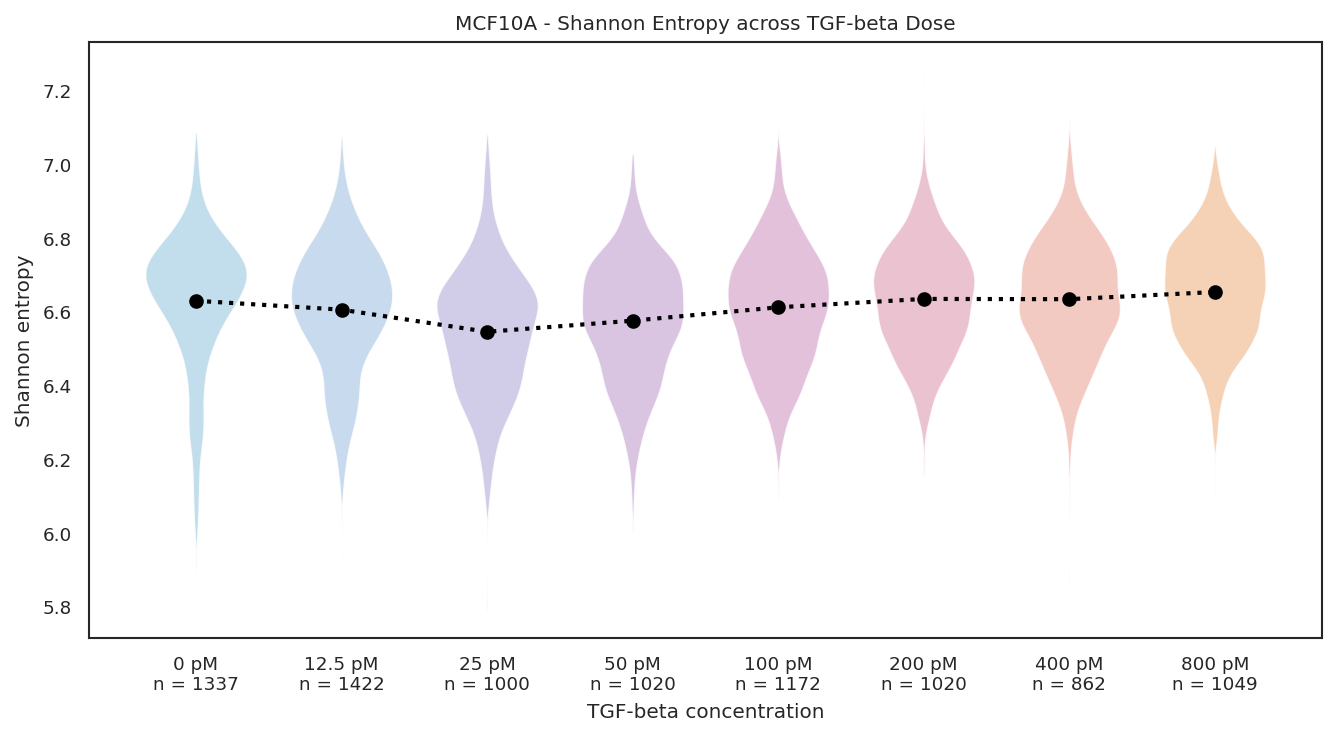

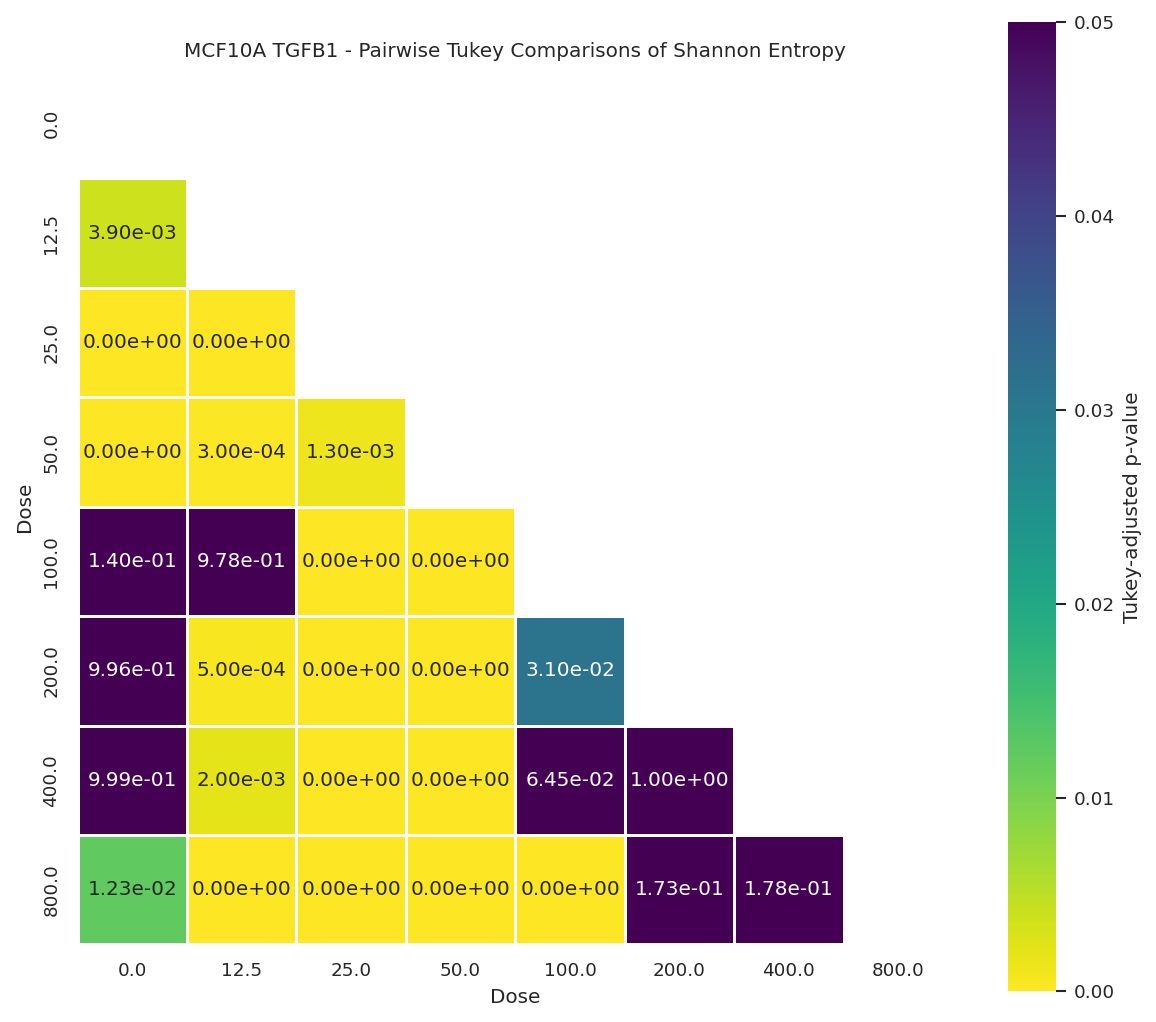

In [3]:
entropy_groups = dose_groups('Shannon_entropy')
entropy_means = [values.mean() for values in entropy_groups]
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(x, entropy_means, 'o--', linewidth=2, markersize=5)
ax.set_xticks(x); ax.set_xticklabels(DOSE_LABELS); ax.set_xlabel('TGF-beta concentration (pM)'); ax.set_ylabel('Shannon entropy')
ax.set_title('MCF10A - Shannon Entropy across TGF-beta Dose'); fig.tight_layout(); save_figure(fig, 'panel04_shannon_entropy_trajectory'); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
parts = ax.violinplot(entropy_groups, positions=x, widths=0.7, showmeans=False, showmedians=False, showextrema=False)
for body, color in zip(parts['bodies'], PASTEL_COLORS): body.set_facecolor(color); body.set_alpha(0.85)
ax.plot(x, entropy_means, ':o', linewidth=2, markersize=6, color='black')
ax.set_xticks(x); ax.set_xticklabels([f'{dose:g} pM\nn = {int(counts.loc[dose])}' for dose in DOSE_ORDER])
ax.set_xlabel('TGF-beta concentration'); ax.set_ylabel('Shannon entropy'); ax.set_title('MCF10A - Shannon Entropy across TGF-beta Dose')
fig.tight_layout(); save_figure(fig, 'panel05_shannon_entropy_violin'); plt.show()

entropy_tukey = pairwise_tukeyhsd(cells['Shannon_entropy'], cells['Dose_pM'], alpha=0.05)
entropy_df = pd.DataFrame(entropy_tukey._results_table.data[1:], columns=entropy_tukey._results_table.data[0]); entropy_df['p-adj'] = entropy_df['p-adj'].astype(float)
entropy_p = pd.DataFrame(np.nan, index=DOSE_ORDER, columns=DOSE_ORDER)
for _, row in entropy_df.iterrows(): entropy_p.loc[float(row['group1']), float(row['group2'])] = row['p-adj']; entropy_p.loc[float(row['group2']), float(row['group1'])] = row['p-adj']
entropy_p.to_csv(SOURCE / 'MCF10A_panel06_shannon_entropy_tukey_matrix.csv')
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(entropy_p, mask=np.triu(np.ones_like(entropy_p, dtype=bool)), annot=True, fmt='.2e', cmap='viridis_r', vmin=0, vmax=0.05, linewidths=0.5, square=True, cbar_kws={'label':'Tukey-adjusted p-value'}, ax=ax)
ax.set_title('MCF10A TGFB1 - Pairwise Tukey Comparisons of Shannon Entropy'); ax.set_xlabel('Dose'); ax.set_ylabel('Dose')
fig.tight_layout(); save_figure(fig, 'panel06_shannon_entropy_tukey'); plt.show()

## KS and 76GS plots

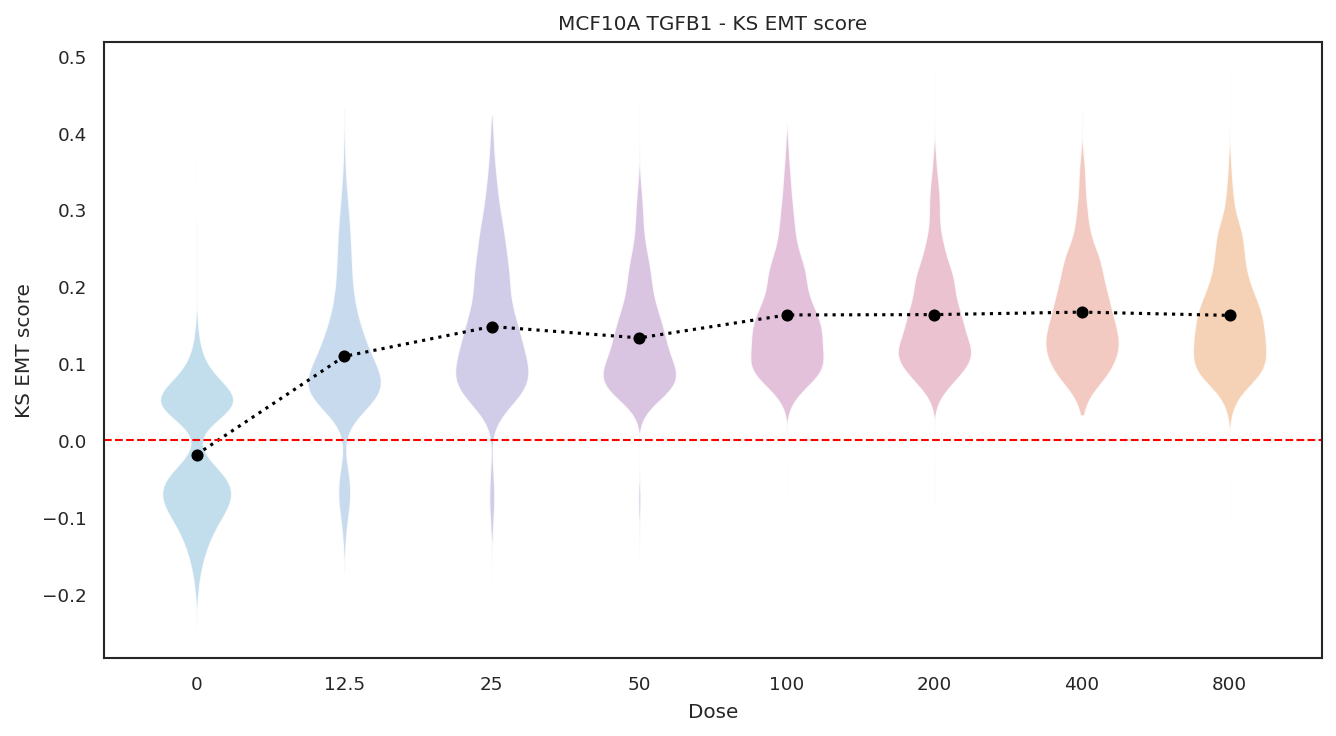

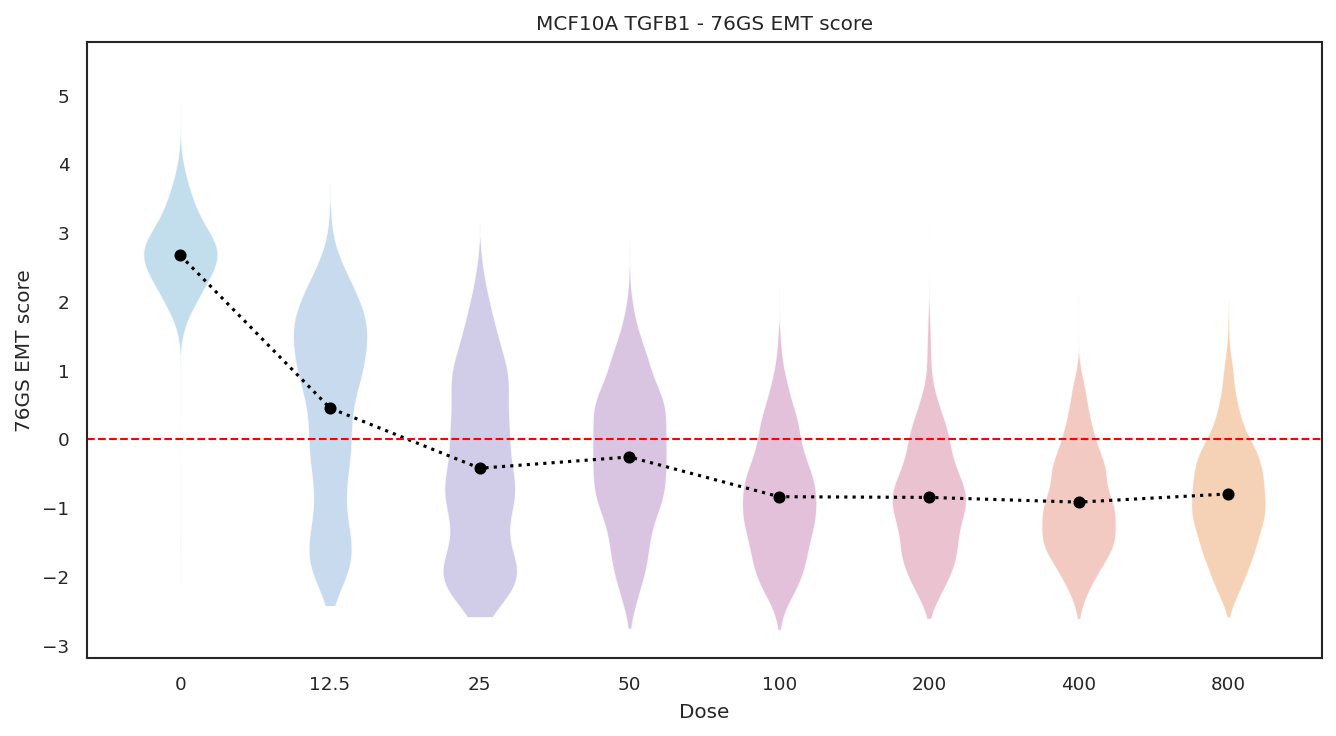

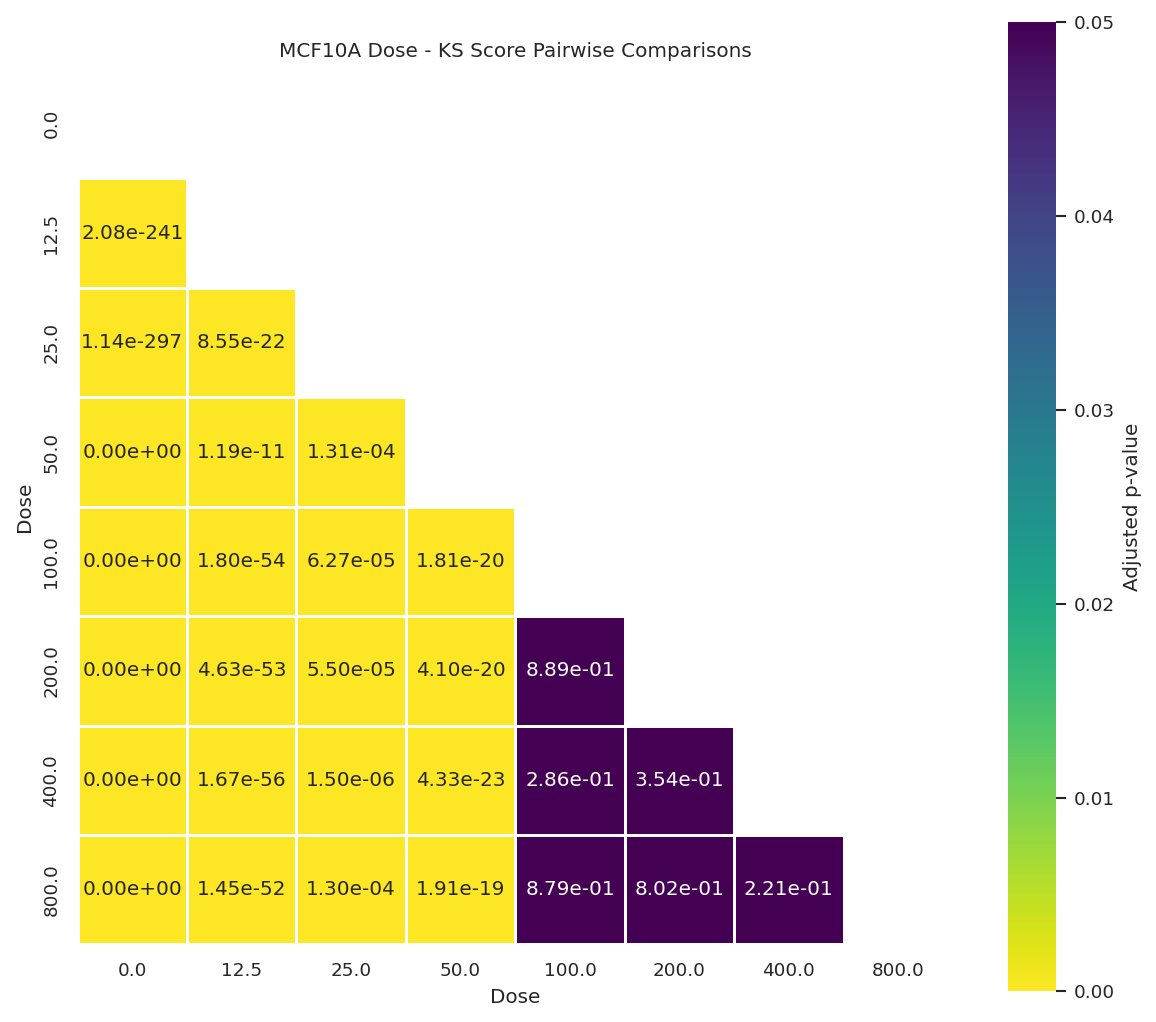

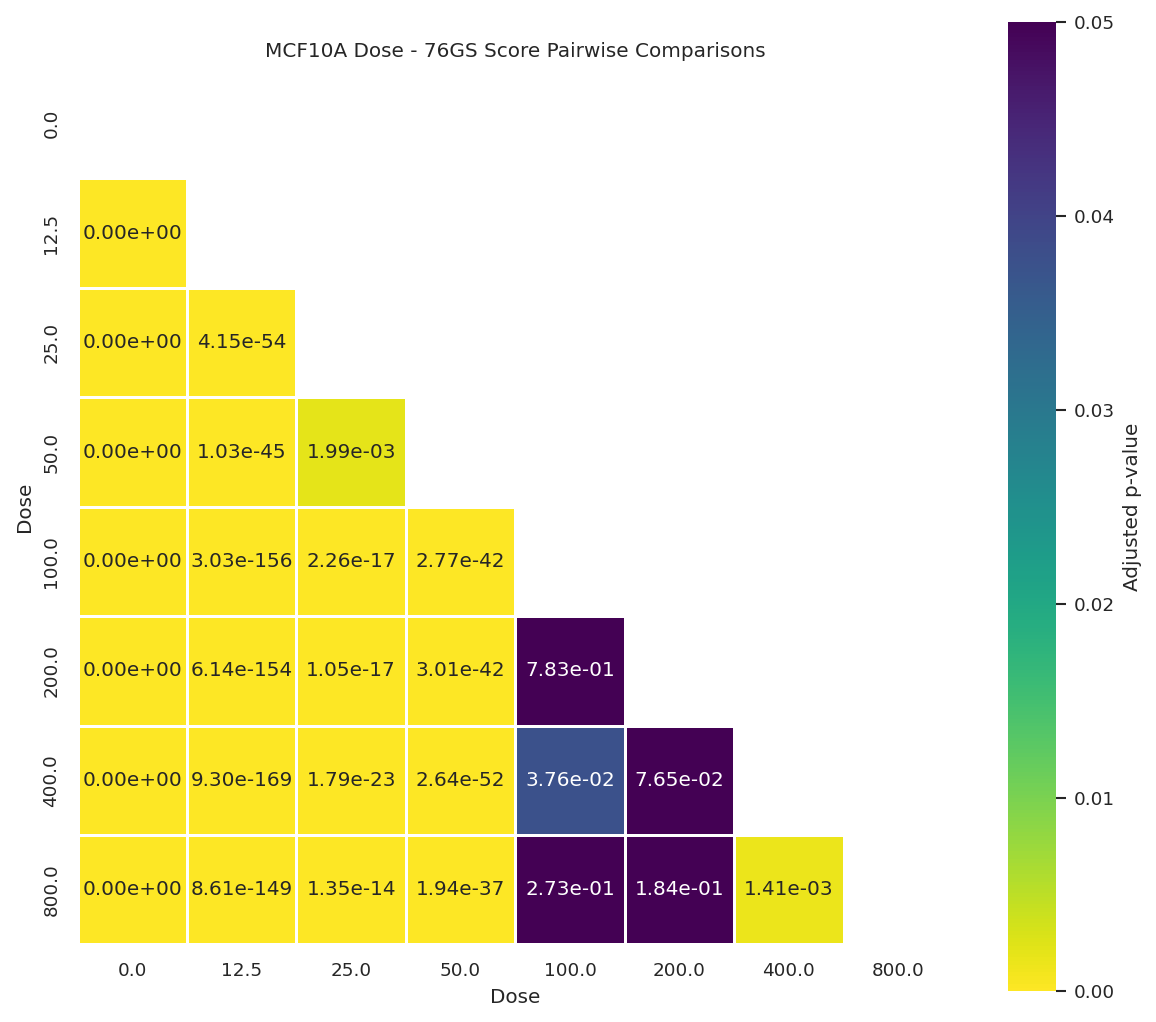

In [4]:
for score, label, name in [('KS_score','KS EMT score','panel07_ks'), ('GS76_score','76GS EMT score','panel08_gs76')]:
    groups = dose_groups(score); means = [values.mean() for values in groups]
    fig, ax = plt.subplots(figsize=(9, 5))
    parts = ax.violinplot(groups, positions=x, showmeans=False, showmedians=False, showextrema=False)
    for body, color in zip(parts['bodies'], PASTEL_COLORS): body.set_facecolor(color); body.set_alpha(0.85)
    ax.scatter(x, means, color='black', s=25, zorder=3); ax.plot(x, means, ':', linewidth=1.5, color='black', zorder=2); ax.axhline(0, linestyle='--', linewidth=1, color='red')
    ax.set_xticks(x); ax.set_xticklabels(DOSE_LABELS); ax.set_xlabel('Dose'); ax.set_ylabel(label); ax.set_title(f'MCF10A TGFB1 - {label}')
    fig.tight_layout(); save_figure(fig, name); plt.show()

def pairwise_fdr(column):
    rows=[]
    for first, second in combinations(DOSE_ORDER, 2):
        a=cells.loc[cells.Dose_pM==first,column].dropna(); b=cells.loc[cells.Dose_pM==second,column].dropna(); stat,p=ttest_ind(a,b,equal_var=False); rows.append({'Dose1':first,'Dose2':second,'t_stat':stat,'p':p,'n1':len(a),'n2':len(b)})
    result=pd.DataFrame(rows); result['p_adj']=multipletests(result.p,method='fdr_bh')[1]; matrix=pd.DataFrame(np.nan,index=DOSE_ORDER,columns=DOSE_ORDER)
    for _, row in result.iterrows(): matrix.loc[row.Dose1,row.Dose2]=row.p_adj; matrix.loc[row.Dose2,row.Dose1]=row.p_adj
    return result,matrix

for score, label, name in [('KS_score','KS','panel09_ks_pairwise'),('GS76_score','76GS','panel10_gs76_pairwise')]:
    result, matrix = pairwise_fdr(score); result.to_csv(SOURCE / f'MCF10A_{name}.csv', index=False); matrix.to_csv(SOURCE / f'MCF10A_{name}_matrix.csv')
    fig, ax = plt.subplots(figsize=(8,7)); sns.heatmap(matrix, mask=np.triu(np.ones_like(matrix,dtype=bool)), annot=True, fmt='.2e', cmap='viridis_r', vmin=0, vmax=0.05, linewidths=0.5, square=True, cbar_kws={'label':'Adjusted p-value'}, ax=ax)
    ax.set_title(f'MCF10A Dose - {label} Score Pairwise Comparisons'); ax.set_xlabel('Dose'); ax.set_ylabel('Dose'); fig.tight_layout(); save_figure(fig,name); plt.show()

## Correlation plots

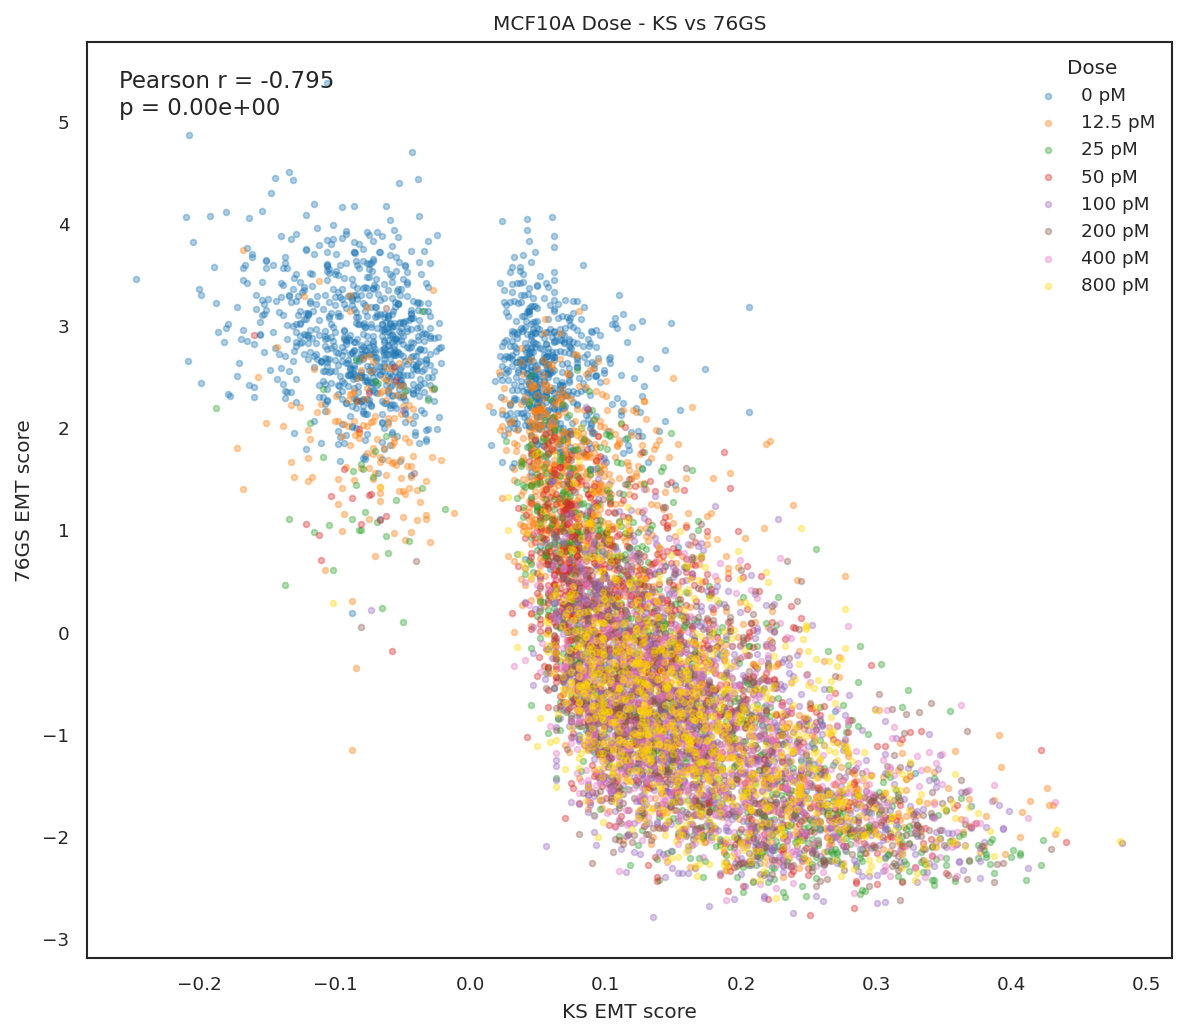

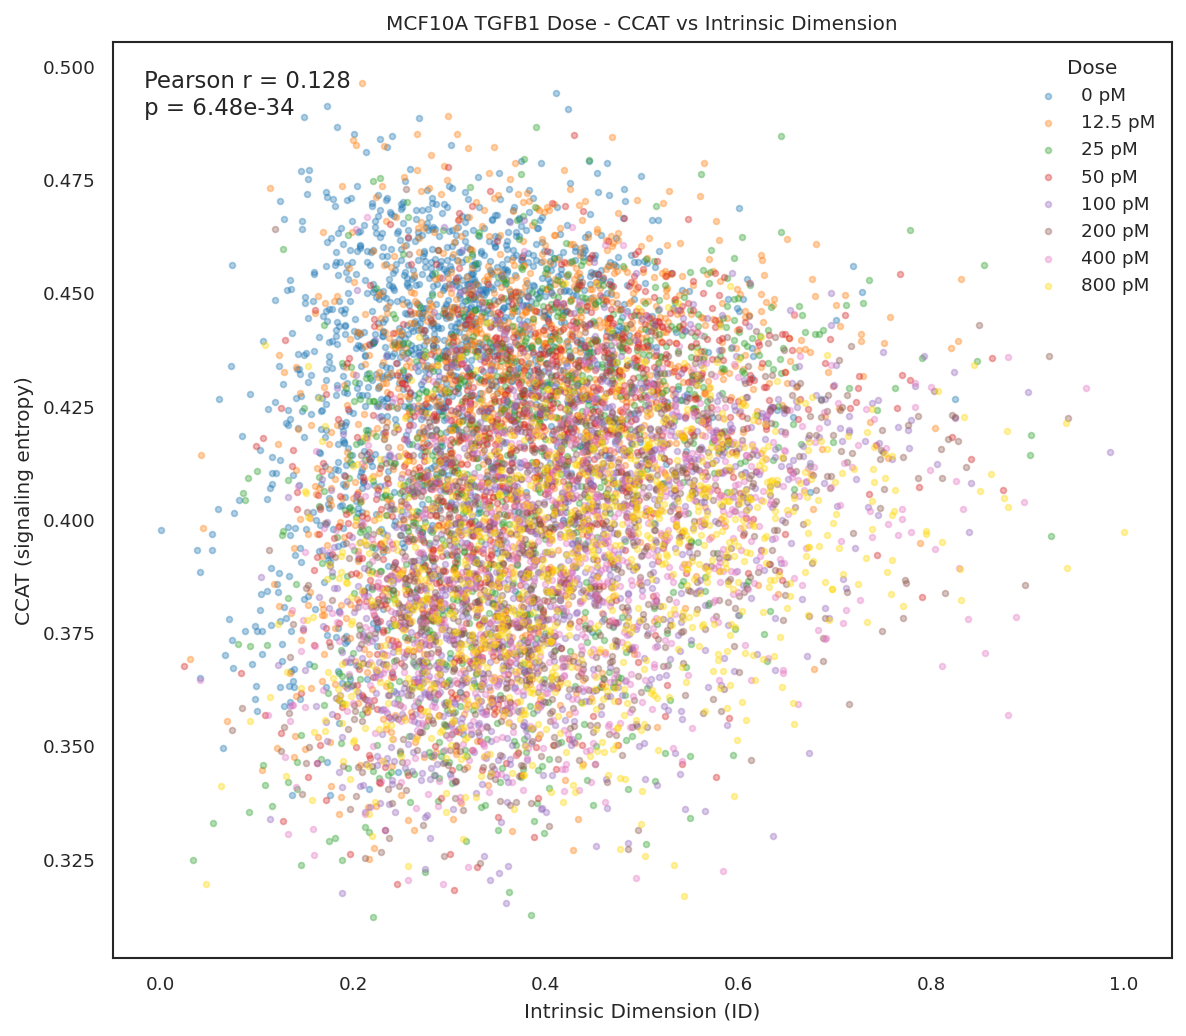

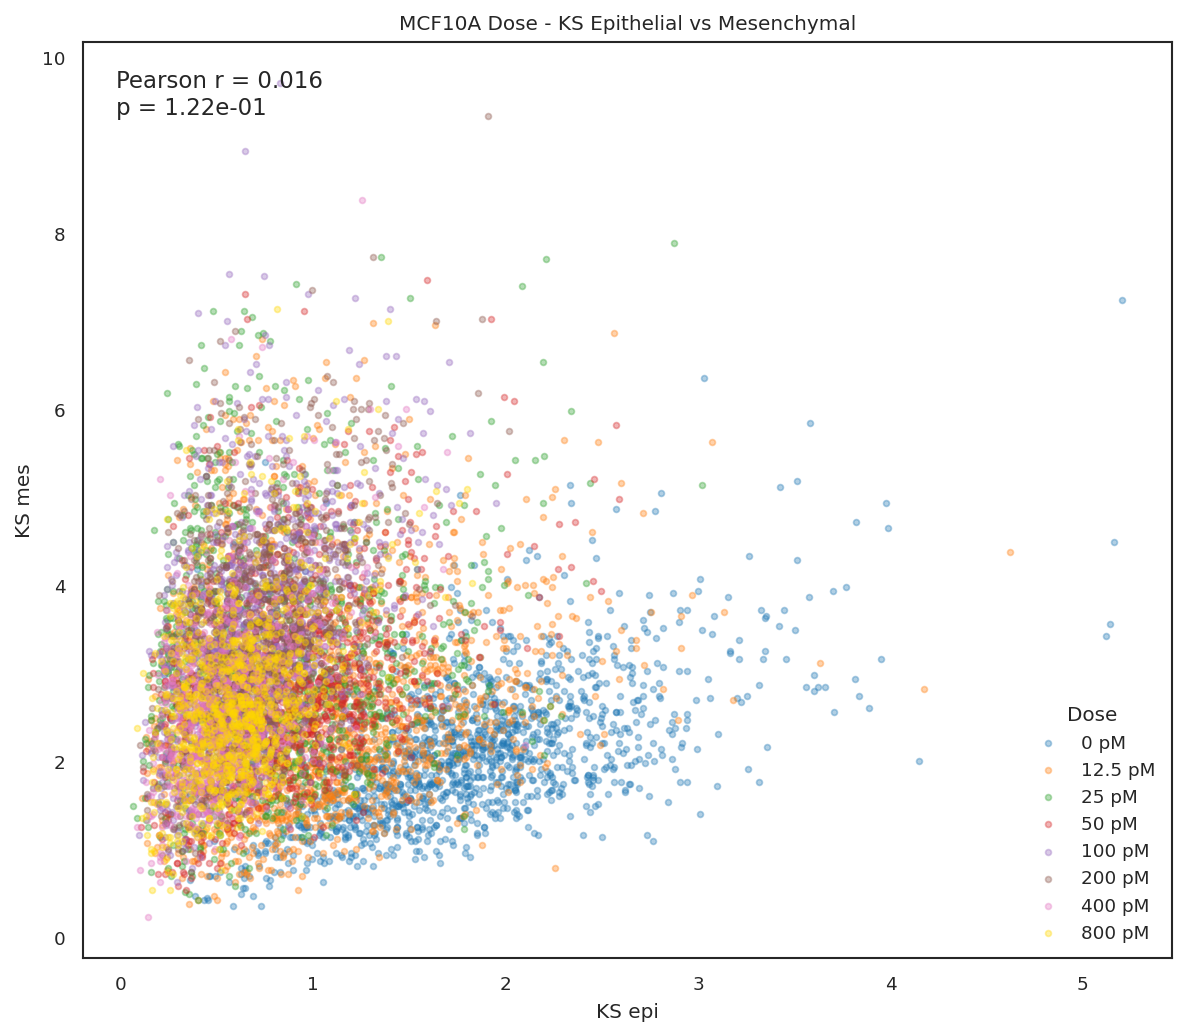

In [8]:
def scatter_by_dose(xcol, ycol, xlabel, ylabel, title, name):
    data = cells[[xcol, ycol, 'Dose_pM']].dropna()
    pr = pearsonr(data[xcol], data[ycol])
    fig, ax = plt.subplots(figsize=(8, 7))
    for dose in DOSE_ORDER:
        subset = data[data.Dose_pM == dose]
        ax.scatter(subset[xcol], subset[ycol], s=8, alpha=0.35, color=DOSE_COLORS[dose], label=f'{dose:g} pM')
    ax.text(0.03, 0.97, f'Pearson r = {pr.statistic:.3f}\np = {pr.pvalue:.2e}', transform=ax.transAxes, ha='left', va='top', fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(title='Dose', frameon=False)
    fig.tight_layout()
    save_figure(fig, name)
    plt.show()

scatter_by_dose('KS_score', 'GS76_score', 'KS EMT score', '76GS EMT score', 'MCF10A Dose - KS vs 76GS', 'panel11_ks_vs_gs76')
scatter_by_dose('ID', 'CCAT', 'Intrinsic Dimension (ID)', 'CCAT (signaling entropy)', 'MCF10A TGFB1 Dose - CCAT vs Intrinsic Dimension', 'panel12_id_vs_ccat')
scatter_by_dose('KS_epi_component', 'KS_mes_component', 'KS epi', 'KS mes', 'MCF10A Dose - KS Epithelial vs Mesenchymal', 'panel13_ks_epi_vs_mes')